# H&M fashion data: exploration, early-winner backtest and recommendation baselines

**Data:** Kaggle competition *H&M Personalized Fashion Recommendations* (add it as an input to this notebook and accept the rules on its Data tab).

**What this notebook does**

1. Loads the three tables and runs sanity checks.
2. Shows how short-lived fashion products are, and how concentrated sales are across products.
3. **Early-winner backtest:** can the first 1, 2, 3, 5 or 7 days of sales predict which products become winners over the following seven weeks?
4. **Recommendation baselines** scored with the competition metric (MAP@12).

**What this data cannot show** (worth saying out loud when presenting): there are no clicks or views, no returns, no stock levels and no record of what was promoted. Purchases stand in for demand. Prices are rescaled. The licence is non-commercial, so this is a demo only.

In [1]:
import os, gc, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import lightgbm as lgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.grid"] = True

# Where the three CSV files live: set HM_DATA_DIR, or put them in ./data, or run on Kaggle.
hits = (glob.glob("data/articles.csv") + glob.glob("/kaggle/input/*/articles.csv")
        + glob.glob("/kaggle/input/*/*/articles.csv"))
DATA = os.environ.get("HM_DATA_DIR") or os.path.dirname(hits[0])
DATA = DATA.rstrip("/") + "/"
print(DATA, os.listdir(DATA))

data/ ['customers.csv', 'articles.csv', 'transactions_train.csv']


## 1. Load

`article_id` has leading zeros in the CSV. It is read as an integer here to save memory, which is fine for joins. (Only a competition submission file needs the zero-padded 10-character string.) Customer IDs are long hashes, so they are swapped for a compact integer.

In [2]:
articles = pd.read_csv(DATA + "articles.csv", dtype={"article_id": "int32"})
customers = pd.read_csv(DATA + "customers.csv")

tx = pd.read_csv(
    DATA + "transactions_train.csv",
    dtype={"article_id": "int32", "price": "float32", "sales_channel_id": "int8"},
    parse_dates=["t_dat"],
)

# compact integer customer key
cust_key = pd.Series(np.arange(len(customers), dtype="int32"), index=customers["customer_id"].values)
tx["cid"] = tx["customer_id"].map(cust_key).astype("int32")
tx = tx.drop(columns=["customer_id"])
customers["cid"] = np.arange(len(customers), dtype="int32")
gc.collect()

print("articles    ", articles.shape)
print("customers   ", customers.shape)
print("transactions", tx.shape)
tx.head()

articles     (105542, 25)
customers    (1371980, 8)
transactions (31788324, 5)


,t_dat,article_id,price,sales_channel_id,cid
0,2018-09-20,663713001,0.050831,2,2
1,2018-09-20,541518023,0.030492,2,2
2,2018-09-20,505221004,0.015237,2,7
3,2018-09-20,685687003,0.016932,2,7
4,2018-09-20,685687004,0.016932,2,7


## 2. Sanity checks

In [3]:
DATA_START, DATA_END = tx["t_dat"].min(), tx["t_dat"].max()
print("date range:", DATA_START.date(), "to", DATA_END.date(), f"({(DATA_END - DATA_START).days + 1} days)")
print("customers who bought:", tx['cid'].nunique(), "of", len(customers))
print("articles sold:       ", tx['article_id'].nunique(), "of", len(articles))
print("online share of rows (channel 2):", round((tx['sales_channel_id'] == 2).mean(), 3))
print()
print("nulls in customers:")
print(customers.isna().mean().round(3))

date range: 2018-09-20 to 2020-09-22 (734 days)
customers who bought: 1362281 of 1371980
articles sold:        104547 of 105542
online share of rows (channel 2): 0.704

nulls in customers:
customer_id               0.000
FN                        0.652
Active                    0.662
club_member_status        0.004
fashion_news_frequency    0.012
age                       0.012
postal_code               0.000
cid                       0.000
dtype: float64


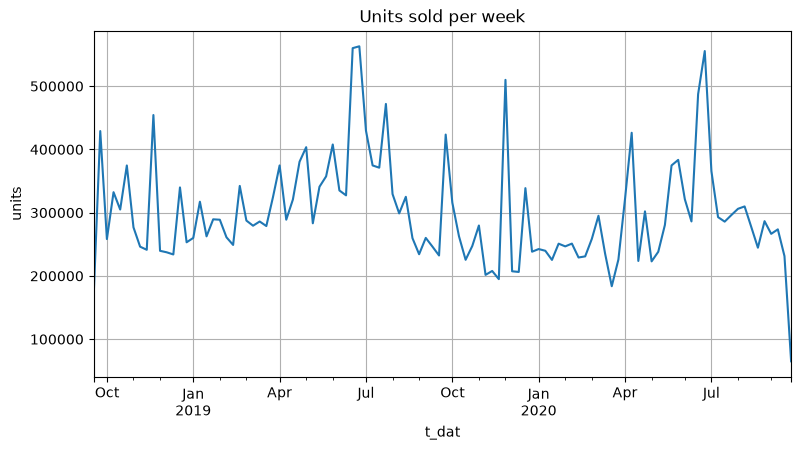

purchases per customer over two years: median 9.0 | mean 23.3 | 90th percentile 60.0


In [4]:
weekly = tx.set_index("t_dat").resample("W")["price"].agg(["size", "sum"])
fig, ax = plt.subplots()
weekly["size"].plot(ax=ax)
ax.set_title("Units sold per week")
ax.set_ylabel("units")
plt.show()

per_cust = tx.groupby("cid").size()
print("purchases per customer over two years: median", per_cust.median(), "| mean", round(per_cust.mean(), 1),
      "| 90th percentile", per_cust.quantile(0.9))

## 3. How short-lived are products, and how concentrated are sales?

`first_sale` is the first date an article appears in the data, used as its launch date. Articles first seen in the opening eight weeks are excluded from lifecycle analysis, because they may have launched before the data starts.

articles with an observed launch: 67694 of 104547


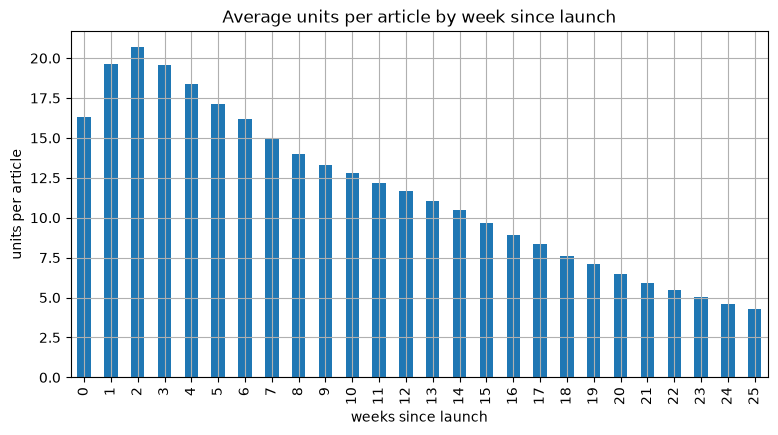

share of 26-week sales that happen in the first 4 weeks: 0.253
share in the first 8 weeks: 0.474


In [5]:
first_sale = tx.groupby("article_id")["t_dat"].min().rename("first_sale")
tx = tx.join(first_sale, on="article_id")
tx["age"] = (tx["t_dat"] - tx["first_sale"]).dt.days.astype("int16")

CENSOR_DAYS = 56
launched_in_window = first_sale[first_sale >= DATA_START + pd.Timedelta(days=CENSOR_DAYS)]
print("articles with an observed launch:", len(launched_in_window), "of", len(first_sale))

# average sales curve by product age (weeks since launch), for articles with at least 26 weeks of follow-up
ok = first_sale[(first_sale >= DATA_START + pd.Timedelta(days=CENSOR_DAYS)) &
                (first_sale <= DATA_END - pd.Timedelta(days=182))].index
sub = tx[tx["article_id"].isin(ok) & (tx["age"] < 182)]
curve = sub.groupby(sub["age"] // 7).size() / len(ok)
fig, ax = plt.subplots()
curve.plot(kind="bar", ax=ax)
ax.set_title("Average units per article by week since launch")
ax.set_xlabel("weeks since launch"); ax.set_ylabel("units per article")
plt.show()
print("share of 26-week sales that happen in the first 4 weeks:", round(curve.iloc[:4].sum() / curve.sum(), 3))
print("share in the first 8 weeks:", round(curve.iloc[:8].sum() / curve.sum(), 3))

50% of revenue comes from 2,007 articles = 4.9% of articles sold in the period
80% of revenue comes from 6,290 articles = 15.4% of articles sold in the period
90% of revenue comes from 9,937 articles = 24.4% of articles sold in the period


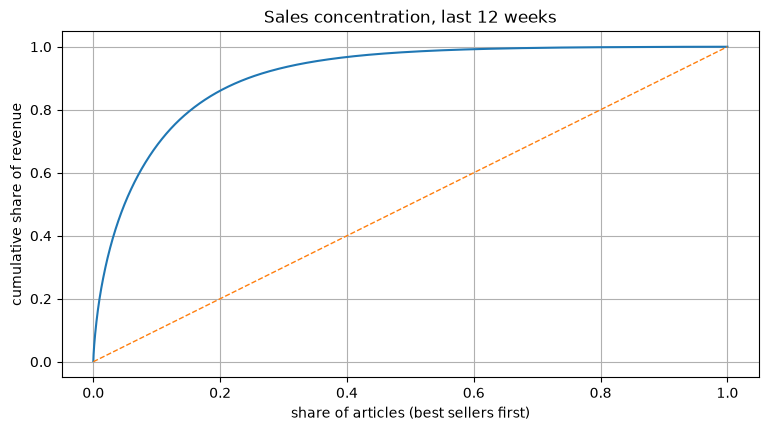

In [6]:
# Concentration: what share of articles produces 80% of revenue? (last 12 weeks, so only live products count)
recent = tx[tx["t_dat"] > DATA_END - pd.Timedelta(days=84)]
rev = recent.groupby("article_id")["price"].sum().sort_values(ascending=False)
cum = rev.cumsum() / rev.sum()
share_articles = np.arange(1, len(rev) + 1) / len(rev)

for target in (0.5, 0.8, 0.9):
    k = int(np.searchsorted(cum.values, target)) + 1
    print(f"{int(target*100)}% of revenue comes from {k:,} articles = {k/len(rev):.1%} of articles sold in the period")

fig, ax = plt.subplots()
ax.plot(share_articles, cum.values)
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
ax.set_xlabel("share of articles (best sellers first)"); ax.set_ylabel("cumulative share of revenue")
ax.set_title("Sales concentration, last 12 weeks")
plt.show()

## 4. Early-winner backtest

**Question:** after only the first few days on sale, can we tell which products will be winners?

**Set-up**

- One row per article with an observed launch and at least 8 weeks of follow-up.
- **Signal:** sales in the first `W` days (tested for W = 1, 2, 3, 5, 7), plus product attributes.
- **Target:** units sold in days 7 to 55 after launch (weeks 2 to 8). The target is the same for every `W`, so the comparison is fair.
- **Winner:** top 10% of articles by that target.
- **Split by time:** train on earlier launches, test on later ones, with a gap so no training target overlaps the test period.

**Two predictors are compared**

- *Naive:* rank articles by units sold in the first `W` days.
- *Model:* gradient-boosted trees (LightGBM) on early-sales features and product attributes.

**Reading the results**

- *Rank correlation:* how well the predicted order matches the real order (1 is perfect).
- *Winners caught:* of the true top 10%, the share that the prediction also placed in its top 10%. Random picking would give 10%.
- *Units captured:* future units in the predicted top 10%, as a share of future units in the true top 10%.

Caveat: with no stock data, a product that sold out early looks like a weak seller here.

In [7]:
HORIZON = 56          # days of follow-up needed
TARGET_FROM = 7       # target window is day 7 .. HORIZON-1
WINDOWS = [1, 2, 3, 5, 7]

elig = first_sale[(first_sale >= DATA_START + pd.Timedelta(days=CENSOR_DAYS)) &
                  (first_sale <= DATA_END - pd.Timedelta(days=HORIZON))]
ev = tx[tx["article_id"].isin(elig.index) & (tx["age"] < HORIZON)][
    ["article_id", "cid", "price", "sales_channel_id", "age"]]
print("eligible articles:", len(elig), "| transactions used:", len(ev))

target = ev[ev["age"] >= TARGET_FROM].groupby("article_id").size().reindex(elig.index).fillna(0).rename("y")

ATTRS = ["product_type_no", "graphical_appearance_no", "colour_group_code", "perceived_colour_value_id",
         "department_no", "index_group_no", "section_no", "garment_group_no"]
art_attr = articles.set_index("article_id")[ATTRS]


def build_features(W):
    e = ev[ev["age"] < W].assign(online=lambda d: (d["sales_channel_id"] == 2).astype("float32"))
    g = e.groupby("article_id")
    f = pd.DataFrame(index=elig.index)
    f["units"] = g.size()
    f["revenue"] = g["price"].sum()
    f["buyers"] = g["cid"].nunique()
    f["online_share"] = g["online"].mean()
    f["active_days"] = g["age"].nunique()
    f["avg_price"] = g["price"].mean()
    f["units_day0"] = e[e["age"] == 0].groupby("article_id").size()
    f["units_last_day"] = e[e["age"] == W - 1].groupby("article_id").size()
    fill0 = ["units", "revenue", "buyers", "active_days", "units_day0", "units_last_day"]
    f[fill0] = f[fill0].fillna(0)
    f["units_per_buyer"] = f["units"] / f["buyers"].replace(0, np.nan)
    f["last_vs_first"] = f["units_last_day"] / f["units_day0"].replace(0, np.nan)
    f["launch_month"] = elig.dt.month
    f["launch_dow"] = elig.dt.dayofweek
    f = f.join(art_attr)
    return f


# time-based split
test_start = elig.quantile(0.8)
train_idx = elig[elig < test_start - pd.Timedelta(days=HORIZON)].index
test_idx = elig[elig >= test_start].index
print("train launches:", len(train_idx), "| test launches:", len(test_idx), "| test starts", test_start.date())

eligible articles: 61317 | transactions used: 8965026
train launches: 43411 | test launches: 12336 | test starts 2020-03-09


In [8]:
def evaluate(pred, y, top=0.10):
    k = max(1, int(len(y) * top))
    true_top = set(y.sort_values(ascending=False).index[:k])
    pred_top = pd.Series(pred, index=y.index).sort_values(ascending=False).index[:k]
    caught = len(true_top.intersection(pred_top)) / k
    captured = y.loc[pred_top].sum() / max(1, y.loc[list(true_top)].sum())
    rho = spearmanr(pred, y.values).correlation
    return {"rank_corr": rho, "winners_caught": caught, "units_captured": captured}


results, models = [], {}
for W in WINDOWS:
    F = build_features(W)
    Xtr, Xte = F.loc[train_idx], F.loc[test_idx]
    ytr, yte = target.loc[train_idx], target.loc[test_idx]

    naive = evaluate(Xte["units"].values, yte)
    results.append({"days_of_signal": W, "predictor": "naive (early units)", **naive})

    m = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=20,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=0)
    m.fit(Xtr, np.log1p(ytr), categorical_feature=ATTRS)
    pred = m.predict(Xte)
    results.append({"days_of_signal": W, "predictor": "model", **evaluate(pred, yte)})
    models[W] = (m, F.columns)

# attributes only: what can be known before launch (no sales signal at all)
F = build_features(1)
pre_cols = ATTRS + ["launch_month", "launch_dow"]
m0 = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31, verbose=-1, random_state=0)
m0.fit(F.loc[train_idx, pre_cols], np.log1p(target.loc[train_idx]), categorical_feature=ATTRS)
results.append({"days_of_signal": 0, "predictor": "model", **evaluate(m0.predict(F.loc[test_idx, pre_cols]), target.loc[test_idx])})

res = pd.DataFrame(results).sort_values(["days_of_signal", "predictor"]).reset_index(drop=True)
res.round(3)

[LightGBM] [Warning] Met negative value in categorical features, will convert it to NaN
[LightGBM] [Warning] Met negative value in categorical features, will convert it to NaN
[LightGBM] [Warning] Met categorical feature which contains sparse values. Consider renumbering to consecutive integers started from zero
[LightGBM] [Warning] Met negative value in categorical features, will convert it to NaN
[LightGBM] [Warning] Met negative value in categorical features, will convert it to NaN
[LightGBM] [Warning] Met negative value in categorical features, will convert it to NaN
[LightGBM] [Warning] Met negative value in categorical features, will convert it to NaN
[LightGBM] [Warning] Met categorical feature which contains sparse values. Consider renumbering to consecutive integers started from zero
[LightGBM] [Warning] Met negative value in categorical features, will convert it to NaN
[LightGBM] [Warning] Met negative value in categorical features, will convert it to NaN
[LightGBM] [Warning]

,days_of_signal,predictor,rank_corr,winners_caught,units_captured
0,0,model,0.829,0.471,0.673
1,1,model,0.837,0.490,0.705
2,1,naive (early units),0.452,0.342,0.507
3,2,model,0.846,0.533,0.747
4,2,naive (early units),0.620,0.370,0.557
5,3,model,0.851,0.539,0.752
6,3,naive (early units),0.685,0.398,0.585
7,5,model,0.862,0.565,0.776
8,5,naive (early units),0.741,0.427,0.625
9,7,model,0.873,0.586,0.796


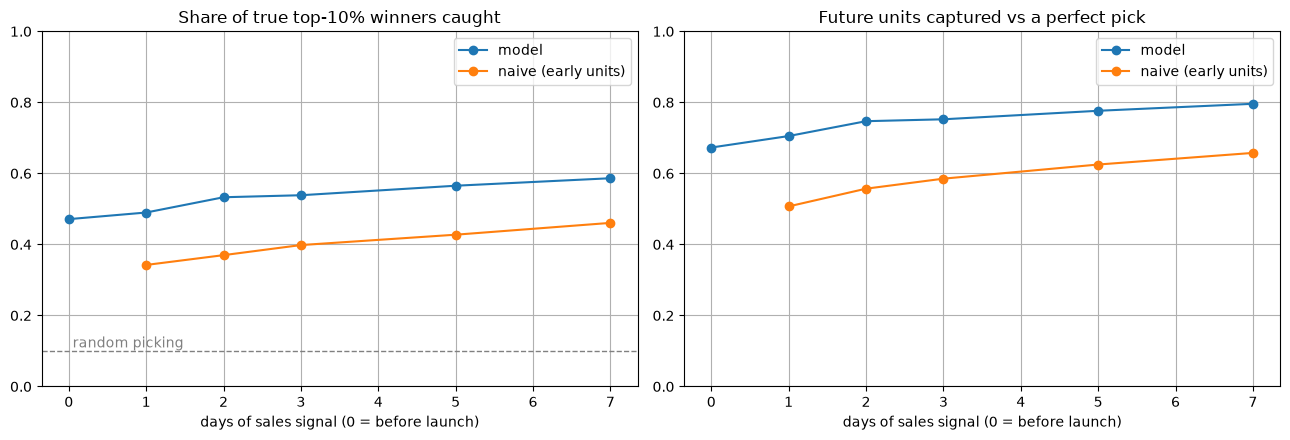

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, grp in res.groupby("predictor"):
    grp = grp.sort_values("days_of_signal")
    axes[0].plot(grp["days_of_signal"], grp["winners_caught"], marker="o", label=name)
    axes[1].plot(grp["days_of_signal"], grp["units_captured"], marker="o", label=name)
axes[0].axhline(0.10, linestyle="--", linewidth=1, color="grey")
axes[0].text(0.05, 0.11, "random picking", color="grey")
axes[0].set_title("Share of true top-10% winners caught"); axes[0].set_xlabel("days of sales signal (0 = before launch)")
axes[1].set_title("Future units captured vs a perfect pick"); axes[1].set_xlabel("days of sales signal (0 = before launch)")
for ax in axes:
    ax.set_ylim(0, 1); ax.legend()
plt.tight_layout(); plt.show()

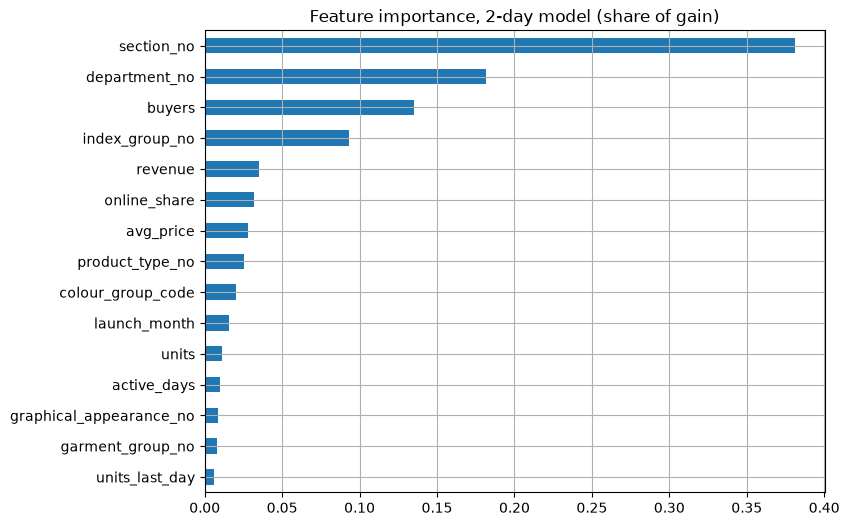

In [10]:
# Which signals does the 2-day model lean on?
m, cols = models[2]
imp = pd.Series(m.booster_.feature_importance(importance_type="gain"), index=cols).sort_values()
imp = imp / imp.sum()
fig, ax = plt.subplots(figsize=(8, 6))
imp.tail(15).plot(kind="barh", ax=ax)
ax.set_title("Feature importance, 2-day model (share of gain)")
plt.show()

### How to read this for a retailer

- The gap between **0 days** (attributes only) and **1 to 2 days** shows how much a tiny amount of real demand is worth compared with predicting before launch.
- The gap between **naive** and **model** shows what machine learning adds over simply sorting by early sales. If it is small, the cheap rule is the right first version.
- The curve from 2 to 7 days shows what waiting buys. If it flattens early, reorder decisions can be made early.

With real retailer data the same backtest gets stronger inputs: views and add-to-cart per impression, size-level sell-through, stock-outs, returns and marketing exposure.

## 5. Recommendation baselines (MAP@12)

The competition task: for each customer, list 12 articles they are likely to buy in the next 7 days. Here the last week of data is held out as the answer key.

**MAP@12** gives credit for each correct article, with more credit the higher it sits in the list, averaged over customers who bought something that week.

Baselines, from simplest up:

1. **Popular:** last week's 12 best sellers for everyone.
2. **Repurchase + popular:** each customer's own recent purchases first, then best sellers.
3. **Repurchase + bought-together + popular:** adds, for each recent purchase, the article most often bought by the same customers.

In [11]:
VAL_START = DATA_END - pd.Timedelta(days=6)
train = tx[tx["t_dat"] < VAL_START][["t_dat", "cid", "article_id"]]
val = tx[tx["t_dat"] >= VAL_START]
truth = val.groupby("cid")["article_id"].apply(set)
print("validation week:", VAL_START.date(), "to", DATA_END.date(), "| customers who bought:", len(truth))

# how much of the validation week is new product?
new_cut = VAL_START - pd.Timedelta(days=28)
fs = first_sale.reindex(val["article_id"]).values
print("share of validation purchases that are articles launched in the previous 4 weeks or later:",
      round((fs >= np.datetime64(new_cut)).mean(), 3))


def apk(actual, predicted, k=12):
    score, hits, seen = 0.0, 0, set()
    for i, p in enumerate(predicted[:k]):
        if p in actual and p not in seen:
            hits += 1
            score += hits / (i + 1.0)
        seen.add(p)
    return score / min(len(actual), k)


def mapk(preds, truth, k=12):
    return float(np.mean([apk(truth[c], preds(c), k) for c in truth.index]))

validation week: 2020-09-16 to 2020-09-22 | customers who bought: 68984
share of validation purchases that are articles launched in the previous 4 weeks or later: 0.368


In [12]:
# 1) popular: best sellers in the last 7 days of training
last_week = train[train["t_dat"] >= VAL_START - pd.Timedelta(days=7)]
popular = last_week["article_id"].value_counts().index[:12].tolist()

# 2) each customer's purchases in the last 6 weeks, most recent first, then most frequent
hist = train[(train["t_dat"] >= VAL_START - pd.Timedelta(days=42)) & train["cid"].isin(truth.index)]
h = (hist.groupby(["cid", "article_id"]).agg(last=("t_dat", "max"), n=("t_dat", "size")).reset_index()
         .sort_values(["cid", "last", "n"], ascending=[True, False, False]))
own = h.groupby("cid")["article_id"].apply(list)

# 3) bought-together: for each article, the other article most often bought by the same customers (last 8 weeks)
r = train[train["t_dat"] >= VAL_START - pd.Timedelta(days=56)][["cid", "article_id"]].drop_duplicates()
sizes = r.groupby("cid")["article_id"].transform("size")
r = r[(sizes > 1) & (sizes <= 30)]           # skip one-item and very heavy buyers
pairs = r.merge(r, on="cid", suffixes=("", "_other"))
pairs = pairs[pairs["article_id"] != pairs["article_id_other"]]
pc = pairs.groupby(["article_id", "article_id_other"]).size().rename("n").reset_index()
pc = pc[pc["n"] >= 3].sort_values(["article_id", "n"], ascending=[True, False])
partner = pc.drop_duplicates("article_id").set_index("article_id")["article_id_other"].to_dict()
print("articles with a bought-together partner:", len(partner))
del pairs, pc; gc.collect()


def fill(lst, k=12):
    out, seen = [], set()
    for a in lst + popular:
        if a not in seen:
            out.append(a); seen.add(a)
        if len(out) == k:
            break
    return out


def rec_popular(c):
    return popular

def rec_repurchase(c):
    return fill(own.get(c, []))

def rec_together(c):
    mine = own.get(c, [])
    extra = [partner[a] for a in mine if a in partner]
    return fill(mine + extra)


scores = pd.Series({
    "popular": mapk(rec_popular, truth),
    "repurchase + popular": mapk(rec_repurchase, truth),
    "repurchase + bought-together + popular": mapk(rec_together, truth),
}, name="MAP@12")
scores.round(5).to_frame()

articles with a bought-together partner: 13997


,MAP@12
popular,0.00875
repurchase + popular,0.02613
repurchase + bought-together + popular,0.02705


In [13]:
# Where do the hits come from? Split customers by whether they bought anything in the previous 6 weeks.
has_hist = truth.index.isin(own.index)
print("validation customers with purchases in the previous 6 weeks:", round(has_hist.mean(), 3))
for label, mask in (("with recent history", has_hist), ("without", ~has_hist)):
    t = truth[mask]
    print(f"  {label:22s} n={len(t):7d}  MAP@12 = {mapk(rec_together, t):.5f}")

validation customers with purchases in the previous 6 weeks: 0.544
  with recent history    n=  37522  MAP@12 = 0.04305
  without                n=  31462  MAP@12 = 0.00797


### What these baselines teach

- Fashion demand is so short-lived that last week's best sellers plus a customer's own recent purchases is a strong benchmark. Any model has to beat it on the same split before it earns a place.
- The split by purchase history shows where the difficulty is: customers with no recent activity get generic lists.
- This scores **prediction**, not **uplift**. Recommending something a customer was about to buy anyway scores well and adds nothing. Only a live A/B test, on kept revenue per visitor, measures what a ranker is worth.

## Next steps

1. **Two-stage ranker:** generate about 100 candidates per customer (the rules above, plus similar items) and train a LightGBM ranker on them. This is how the top competition entries were built.
2. **Content embeddings for new articles:** embed product images and descriptions so brand-new products get neighbours from day one.
3. **Early-winner model on real data:** swap first-day purchases for views, add-to-cart rate and size-level sell-through, and add stock-outs and returns.